# Systematic Model Reduction (CNN)
Rather than guessing at a smaller architecture, find **where the parameters and compute are**, then apply
standard reduction techniques one at a time and measure each:

1. Replace `Flatten` + large `Dense` with **Global Average Pooling**
2. Replace standard convolutions with **depthwise-separable** convolutions (the MobileNet idea)
3. Apply a **width multiplier** (fewer filters per layer)

Every model gets the same training budget on CIFAR-10.

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

keras.utils.set_random_seed(42)

(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
input_shape = x_train.shape[1:]

In [2]:
# Starting point: the complex model from 7_W_ComplextoSimpleModelCompare.ipynb
def create_complex_model(input_shape):
    return keras.Sequential([
        keras.Input(shape=input_shape),
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(10, activation='softmax'),
    ], name="complex")

baseline = create_complex_model(input_shape)

# Where are the parameters?
total = baseline.count_params()
for layer in baseline.layers:
    if layer.count_params():
        print(f"{layer.name:12s} {layer.count_params():>9,} params  ({layer.count_params() / total:6.1%})")
print(f"{'total':12s} {total:>9,}")

conv2d             896 params  (  0.2%)
conv2d_1        18,496 params  (  5.1%)
conv2d_2        73,856 params  ( 20.5%)
dense          262,656 params  ( 72.8%)
dense_1          5,130 params  (  1.4%)
total          361,034


The first `Dense` layer holds most of the weights: it connects every value of the flattened feature map to 512 units.
Global average pooling collapses each feature map to one number, so the classifier needs far fewer weights.

In [3]:
def create_reduced_model(input_shape, width=1.0, separable=False, global_pool=False, name="reduced"):
    Conv = layers.SeparableConv2D if separable else layers.Conv2D
    f = lambda n: max(8, int(n * width))  # width multiplier
    model = keras.Sequential([keras.Input(shape=input_shape)], name=name)
    model.add(layers.Conv2D(f(32), (3, 3), activation='relu'))  # first layer stays a standard conv (only 3 input channels)
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(Conv(f(64), (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(Conv(f(128), (3, 3), activation='relu'))
    if global_pool:
        model.add(layers.GlobalAveragePooling2D())
        model.add(layers.Dense(f(128), activation='relu'))
    else:
        model.add(layers.MaxPooling2D((2, 2)))
        model.add(layers.Flatten())
        model.add(layers.Dense(512, activation='relu'))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(10, activation='softmax'))
    return model

candidates = [
    baseline,
    create_reduced_model(input_shape, global_pool=True, name="global_pool"),
    create_reduced_model(input_shape, global_pool=True, separable=True, name="gp_separable"),
    create_reduced_model(input_shape, global_pool=True, separable=True, width=0.5, name="gp_sep_width0.5"),
    create_reduced_model(input_shape, global_pool=True, separable=True, width=0.25, name="gp_sep_width0.25"),
]
for m in candidates:
    print(f"{m.name:18s} {m.count_params():>9,} params")

complex              361,034 params
global_pool          111,050 params
gp_separable          29,994 params
gp_sep_width0.5        8,346 params
gp_sep_width0.25       2,514 params


In [4]:
import os
import time
import tempfile
import numpy as np
import pandas as pd

def model_report(name, model, x_test, y_test, train_seconds):
    """Accuracy, size and speed for a trained Keras model."""
    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
    path = os.path.join(tempfile.mkdtemp(), "model.keras")
    model.save(path)
    single = x_test[:1]
    model.predict(single, verbose=0)  # warm-up
    start = time.perf_counter()
    for _ in range(50):
        model(single, training=False)
    single_ms = (time.perf_counter() - start) / 50 * 1e3
    start = time.perf_counter()
    model.predict(x_test, batch_size=256, verbose=0)
    throughput = len(x_test) / (time.perf_counter() - start)
    return {"model": name, "params": model.count_params(), "size_MB": os.path.getsize(path) / 1e6,
            "test_accuracy": accuracy, "test_loss": loss, "train_time_s": train_seconds,
            "latency_1_image_ms": single_ms, "throughput_img_per_s": throughput}

epochs = 15
rows = []
for model in candidates:
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    start = time.perf_counter()
    model.fit(x_train, y_train, epochs=epochs, batch_size=64, validation_split=0.1, verbose=0)
    rows.append(model_report(model.name, model, x_test, y_test, time.perf_counter() - start))
    print(f"{model.name:18s} test accuracy {rows[-1]['test_accuracy']:.3f}")

results = pd.DataFrame(rows).set_index("model")
results["params_vs_baseline"] = results["params"] / results.loc["complex", "params"]
results.round(3)

complex            test accuracy 0.703


global_pool        test accuracy 0.698


gp_separable       test accuracy 0.604


gp_sep_width0.5    test accuracy 0.546


gp_sep_width0.25   test accuracy 0.432


,params,size_MB,test_accuracy,test_loss,train_time_s,latency_1_image_ms,throughput_img_per_s,params_vs_baseline
model,,,,,,,,
complex,361034,4.380,0.703,1.009,161.530,6.407,14957.775,1.000
global_pool,111050,1.378,0.698,0.861,150.114,5.811,15666.049,0.308
gp_separable,29994,0.408,0.604,1.095,107.314,6.389,16257.856,0.083
gp_sep_width0.5,8346,0.148,0.546,1.248,75.328,5.847,22598.191,0.023
gp_sep_width0.25,2514,0.078,0.432,1.531,69.663,6.317,23667.635,0.007


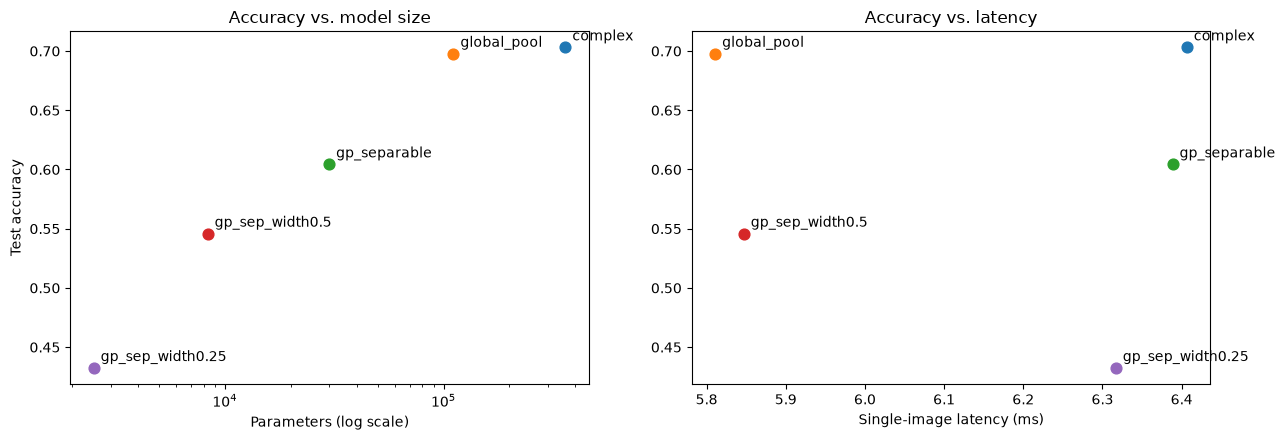

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, row in results.iterrows():
    ax1.scatter(row.params, row.test_accuracy, s=60)
    ax1.annotate(name, (row.params, row.test_accuracy), textcoords="offset points", xytext=(5, 5))
    ax2.scatter(row.latency_1_image_ms, row.test_accuracy, s=60)
    ax2.annotate(name, (row.latency_1_image_ms, row.test_accuracy), textcoords="offset points", xytext=(5, 5))
ax1.set_xscale('log')
ax1.set_xlabel('Parameters (log scale)')
ax1.set_ylabel('Test accuracy')
ax1.set_title('Accuracy vs. model size')
ax2.set_xlabel('Single-image latency (ms)')
ax2.set_title('Accuracy vs. latency')
plt.tight_layout()
plt.show()

## Takeaways
* Removing the oversized `Dense` layer (global average pooling) gives the largest parameter cut - about 70% - for
  almost no accuracy loss.
* Separable convolutions and width multipliers keep shrinking the model, but each step now costs real accuracy:
  past a point there is no free lunch. Pick the smallest model that meets the accuracy requirement.
* Fewer parameters did **not** reduce single-image latency here: for tiny models the fixed per-call framework overhead
  dominates, while batch throughput did improve. Always measure latency on the target hardware and in the serving mode
  (single request vs. batch) you will actually use.
* Next steps: quantization (`8_W_QuantizedLLM.ipynb`), pruning and distillation (`6_W_CompressLLMs.ipynb`).